# Open coding a fictional employee survey

**Northwind Logistics is not a real company.** Every comment in `examples/data/employee_survey_comments.csv` is synthetic. The research context in `examples/data/context.md` is a fictional example. Nothing here is about a real workplace or a real person.

This notebook walks through `automated_grounded_theory` on that file: open coding, an evaluation table, a theme report that groups those codes, a multi-seed comparison, and a Taguette export. `OFFLINE = True` uses a local stand-in for the chat model, so the notebook runs without an API key. Set it to `False` and name a `provider:model` string when you want a live model.


## Grounded theory, and what this package does

Open coding, in the grounded theory tradition, builds codes from the incidents in the data rather than from a list written beforehand (Glaser and Strauss 1967; Glaser 1992). Charmaz (2006/2014) describes the first pass as line-by-line or incident coding: short gerunds, in-vivo phrases when the participant's words do the analytic work, and memos when a passage adds a property, a condition, or a comparison. Constant comparison means each new incident is read against the codes already earned.

This package follows that order.

- The research context sensitizes attention. It is rejected if it contains preset codes.
- The default `review_mode` is `document`. Documents are shuffled with the seed. Passages inside a document stay in reading order. The codebook updates after the document, or after each passage when `batch_size` is 1.
- `batch_size` above 1 packs several passages of the *same* document against one snapshot. That is a milder break in comparison than mixing documents.
- `pipeline=True` runs synthesis of a finished document while the next document is coded, then applies the merge map in chunk order.
- `review_mode="wave"` is opt-in. It weakens constant comparison: passages from several documents can share one frozen codebook, and a later passage can be coded before an earlier one.
- Saturation is a curve of new codes. The package does not decide that categories are saturated (Charmaz).
- `build_themes` is a later round. It groups open codes. It does not mint new codes, and it does not do axial or selective coding.

The mapping from parameters to those sources is in [docs/methodology.md](../docs/methodology.md).


## Install

The library does not install a model provider. Add the extra for the one you call, and `plots` if you want the prevalence chart written to disk.

```bash
pip install automated_grounded_theory
pip install "automated_grounded_theory[xai]"        # XAI_API_KEY
pip install "automated_grounded_theory[openai]"     # OPENAI_API_KEY
pip install "automated_grounded_theory[anthropic]"  # ANTHROPIC_API_KEY
pip install "automated_grounded_theory[ollama]"     # local Ollama, no key
pip install "automated_grounded_theory[plots]"      # matplotlib
```

Other extras are listed in the README (`google`, `mistral`, `groq`, `azure`, `aws`, `cohere`, `huggingface`). No provider is imported until a `provider:model` string names it.


## Choose a provider

A model is either a `provider:model-name` string for LangChain `init_chat_model`, or a `BaseChatModel` you built yourself. Leave `api_key` unset and the provider SDK reads its own environment variable. This package does not contain a key.

```python
# xAI. Extra: xai. Environment: XAI_API_KEY.
model = "xai:grok-4"

# OpenAI. Extra: openai. Environment: OPENAI_API_KEY.
model = "openai:gpt-4o"

# Anthropic. Extra: anthropic. Environment: ANTHROPIC_API_KEY.
model = "anthropic:claude-sonnet-4-5"

# Ollama. Extra: ollama. A local server, no API key.
model = "ollama:llama3.1"
```

In a notebook, call `await aopen_code(...)`. A `provider:model` string is resolved inside that call. A client you already built on the notebook's event loop should be passed as the model object to the async function. The sync wrappers (`open_code`, `build_themes`) work from a notebook too, by running in a worker thread; a client bound to the notebook loop will not work on that thread.

The cell below keeps `OFFLINE = True`. The offline models implement the same structured-output interface as the test fake, with keyword rules for this fictional survey. They are a way to exercise the pipeline, not an analysis.


In [1]:
OFFLINE = True

PROVIDER_EXAMPLES = {
    "xai": "xai:grok-4",
    "openai": "openai:gpt-4o",
    "anthropic": "anthropic:claude-sonnet-4-5",
    "ollama": "ollama:llama3.1",
}

import sys
import tempfile
from pathlib import Path

HERE = Path.cwd().resolve()
ROOT = HERE
for candidate in [HERE, *HERE.parents]:
    if (candidate / "examples" / "data" / "employee_survey_comments.csv").is_file():
        ROOT = candidate
        break

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

if OFFLINE:
    from examples.offline_model import SurveyCoder, SurveyThemer

    model = SurveyCoder()
    theme_model = SurveyThemer()
else:
    # Flip OFFLINE to False and pick any key from PROVIDER_EXAMPLES.
    model = PROVIDER_EXAMPLES["xai"]
    theme_model = model

print("offline" if OFFLINE else "live", type(model).__name__ if OFFLINE else model)
print("data", ROOT / "examples" / "data" / "employee_survey_comments.csv")


offline SurveyCoder
data /workspace/examples/data/employee_survey_comments.csv


## Load the corpus

Each row is one comment. The three answers from a respondent become one document, so the reading stays inside that person's words and `batch_size` can pack those passages together. Department and tenure stay on the document as metadata. They are not codes. The speaker label (`Like`, `Improve`, `Other`) keeps the question next to the comment; the stored quote is the comment itself.


In [2]:
import csv
from collections import Counter

DATA = ROOT / "examples" / "data" / "employee_survey_comments.csv"
CONTEXT_PATH = ROOT / "examples" / "data" / "context.md"
print(CONTEXT_PATH.read_text(encoding="utf-8").splitlines()[0])

QUESTION_SPEAKER = {
    "What do you like most about working here?": "Like",
    "What should we improve?": "Improve",
    "Any other comments?": "Other",
}

by_respondent = {}
with DATA.open(newline="", encoding="utf-8") as handle:
    for row in csv.DictReader(handle):
        by_respondent.setdefault(row["respondent_id"], []).append(row)

corpus = []
for respondent_id, comments in by_respondent.items():
    first = comments[0]
    turns = []
    for row in comments:
        speaker = QUESTION_SPEAKER.get(row["question"], "Comment")
        turns.append(f"{speaker}: {row['comment'].strip()}")
    corpus.append(
        {
            "id": respondent_id,
            "name": respondent_id,
            "text": "\n\n".join(turns),
            "metadata": {
                "respondent_id": respondent_id,
                "department": first["department"],
                "tenure_band": first["tenure_band"],
            },
        }
    )

context = {
    "research_question": (
        "How do employees experience working at Northwind Logistics, "
        "and what drives (or erodes) their engagement?"
    ),
    "population": "Employees of fictional Northwind Logistics",
    "setting": "A fictional mid-size logistics company after a restructure, a systems rollout, and a hybrid-work shift.",
    "sensitizing_concepts": ["engagement", "frontline versus office roles", "tenure"],
    "notes": "FICTIONAL EXAMPLE DATA. Northwind Logistics is not a real company. No preset codes.",
}

blank = "\n\n"
print(len(corpus), "documents,", sum(text.count(blank) + 1 for text in (item["text"] for item in corpus)), "passages")
print("departments", dict(Counter(item["metadata"]["department"] for item in corpus)))
print("---")
print(corpus[0]["name"], corpus[0]["metadata"])
print(corpus[0]["text"])


# Research Context (FICTIONAL EXAMPLE DATA)
50 documents, 150 passages
departments {'Transportation': 8, 'IT': 9, 'Finance': 8, 'Sales': 4, 'Warehouse Operations': 5, 'Planning & Analytics': 6, 'Customer Service': 4, 'HR': 6}
---
R001 {'respondent_id': 'R001', 'department': 'Transportation', 'tenure_band': '<1 year'}
Like: My team. Honestly the people are why I stay.

Improve: Pay. Pay. Pay. We're 10-15% below market and everyone knows it.

Other: Thanks for asking.


## Run open coding

`aopen_code` is the async entry point. `seed=7` shuffles documents and leaves each document's three comments in reading order. `batch_size=3` puts those three comments in one model call. `concurrency=2` caps in-flight calls. `sweep_every=25` compares codes with each other after every 25 passages, and once more at the end. `pipeline=True` overlaps that synthesis with the next document.

The run writes the codebook, segments, memos, saturation curve, and Taguette files to a temporary directory.


In [3]:
from automated_grounded_theory import aopen_code

RUN = Path(tempfile.mkdtemp(prefix="agt-demo-"))
print("output_dir", RUN)
result = await aopen_code(
    corpus,
    context,
    model=model,
    seed=7,
    unit="speaker_turn",
    batch_size=3,
    concurrency=2,
    sweep_every=25,
    review_mode="document",
    pipeline=True,
    output_dir=RUN,
)

order = []
for passage in result.passages:
    if passage["doc_id"] not in order:
        order.append(passage["doc_id"])
print("review_mode", result.metadata.get("review_mode"))
print("passages", len(result.passages), "documents", len(order), "codes", len(result.codebook))
print("first documents in seeded order:", ", ".join(order[:8]))
print("warnings:", result.warnings or "none")


output_dir /tmp/agt-demo-ly05fwei


review_mode document
passages 150 documents 50 codes 32
first documents in seeded order: R025, R036, R015, R032, R011, R049, R012, R017
warnings: none


## Codebook, segments, memos, saturation

The codebook is what survived constant comparison, including merges of labels that named the same incident. Segments are the verbatim quotes. Memos are the passage notes plus one comparison memo and one reflexivity note per document. The saturation figure is a report: new codes per window. `judgment` stays null.


In [4]:
from IPython.display import Markdown, display

def markdown_table(rows, columns):
    header = "| " + " | ".join(columns) + " |"
    rule = "| " + " | ".join("---" for _ in columns) + " |"
    body = []
    for row in rows:
        cells = [str(row.get(column, "")).replace("|", "/").replace("\n", " ") for column in columns]
        body.append("| " + " | ".join(cells) + " |")
    display(Markdown("\n".join([header, rule, *body])))

ranked = sorted(result.codebook, key=lambda entry: (-int(entry.get("frequency") or 0), entry.get("code") or ""))
markdown_table(ranked, ["code", "frequency", "definition"])


| code | frequency | definition |
| --- | --- | --- |
| valuing schedule flexibility | 14 | Incidents of valuing schedule flexibility. |
| staying for the team | 13 | Incidents of staying for the team. |
| wanting better pay | 13 | Describing pay as below what the work is worth. |
| running short of staff | 12 | Describing too few people for the work that remains. |
| using chances to learn | 10 | Incidents of using chances to learn. |
| wanting recognition for the work | 9 | Incidents of wanting recognition for the work. |
| fighting clunky systems | 8 | Incidents of fighting clunky systems. |
| fearing the next layoff | 7 | Incidents of fearing the next layoff. |
| seeing the point of the work | 7 | Incidents of seeing the point of the work. |
| weighing the benefits package | 7 | Incidents of weighing the benefits package. |
| appreciating clearer updates | 6 | Incidents of appreciating clearer updates. |
| weighing inclusion against the talk | 6 | Incidents of weighing inclusion against the talk. |
| asking for a workplace fix | 5 | Incidents of asking for a workplace fix. |
| doubting the survey will change anything | 5 | Incidents of doubting the survey will change anything. |
| finding little to like | 5 | Incidents of finding little to like. |
| missing a promotion path | 5 | Incidents of missing a promotion path. |
| naming a small perk | 4 | Incidents of naming a small perk. |
| sitting through extra meetings | 4 | Incidents of sitting through extra meetings. |
| comparing this place favorably | 3 | Incidents of comparing this place favorably. |
| having a manager who listens | 3 | Incidents of having a manager who listens. |
| asking for mental health support | 2 | Incidents of asking for mental health support. |
| feeling like a number | 2 | Incidents of feeling like a number. |
| feeling safe at work | 2 | Incidents of feeling safe at work. |
| missing cross-department communication | 2 | Incidents of missing cross-department communication. |
| pushing back on micromanaging | 2 | Incidents of pushing back on micromanaging. |
| wanting a say in decisions | 2 | Incidents of wanting a say in decisions. |
| asking for clearer strategy | 1 | Incidents of asking for clearer strategy. |
| asking leaders to own mistakes | 1 | Incidents of asking leaders to own mistakes. |
| calling reviews a box-checking exercise | 1 | Incidents of calling reviews a box-checking exercise. |
| hearing changes through rumors | 1 | Incidents of hearing changes through rumors. |
| keeping autonomy in the work | 1 | Incidents of keeping autonomy in the work. |
| needing manager training | 1 | Incidents of needing manager training. |

In [5]:
sample = []
for segment in result.segments[:8]:
    sample.append(
        {
            "doc_id": segment.get("doc_id"),
            "department": (segment.get("metadata") or {}).get("department", ""),
            "code": segment.get("code"),
            "quote": segment.get("quote"),
        }
    )
markdown_table(sample, ["doc_id", "department", "code", "quote"])
print(f"{len(result.segments)} coded segments in total")


| doc_id | department | code | quote |
| --- | --- | --- | --- |
| R025 | IT | pushing back on micromanaging | Nobody micromanages me. |
| R025 | IT | keeping autonomy in the work | Autonomy. |
| R025 | IT | doubting the survey will change anything | Survey results never lead to anything. |
| R025 | IT | running short of staff | Everyone is tired. |
| R036 | Customer Service | staying for the team | Clear goals on my team, I know what success looks like |
| R036 | Customer Service | wanting a say in decisions | I'd like more say in decisions that affect my work. |
| R036 | Customer Service | staying for the team | I'd recommend Northwind to a friend, but only for certain teams. |
| R015 | HR | valuing schedule flexibility | I like the hybrid schedule but wish it was more consistent across teams |

164 coded segments in total


In [6]:
from collections import Counter

kinds = Counter(memo.get("kind") for memo in result.memos)
print("memo kinds", dict(kinds))
shown = 0
for memo in result.memos:
    if memo.get("kind") not in {"passage", "document", "reflexive"}:
        continue
    print(f"\n[{memo.get('kind')}] {memo.get('doc_id') or ''}")
    print(memo.get("text"))
    shown += 1
    if shown == 3:
        break


memo kinds {'passage': 140, 'document': 54, 'reflexive': 60, 'sweep': 6}

[passage] R025
Compared with the codebook: this passage adds a condition the nearest code does not cover.

[passage] R025
Compared with the codebook: this passage adds a condition the nearest code does not cover.

[passage] R025
Compared with the codebook: this passage adds a condition the nearest code does not cover.


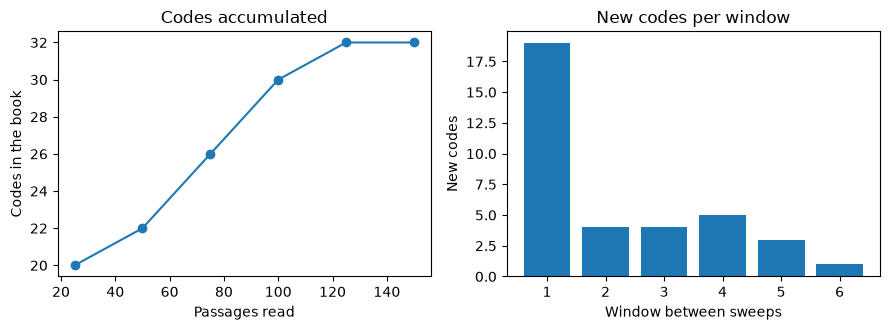

New codes per batch are reported so a researcher can judge saturation. This package does not decide that categories are saturated.
judgment None


In [7]:
import io

import matplotlib.pyplot as plt
from IPython.display import Image, display

points = result.saturation
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].plot(
    [point["cumulative_passages"] for point in points],
    [point["cumulative_codes"] for point in points],
    marker="o",
)
axes[0].set_xlabel("Passages read")
axes[0].set_ylabel("Codes in the book")
axes[0].set_title("Codes accumulated")
axes[1].bar([point["batch"] for point in points], [point["new_codes"] for point in points])
axes[1].set_xlabel("Window between sweeps")
axes[1].set_ylabel("New codes")
axes[1].set_title("New codes per window")
fig.tight_layout()
buffer = io.BytesIO()
fig.savefig(buffer, format="png", bbox_inches="tight")
plt.close(fig)
display(Image(data=buffer.getvalue()))
print(result.saturation_report["note"])
print("judgment", result.saturation_report["judgment"])


## Evaluate

`aevaluate` scores the run without calling a provider when `model` is omitted. Coverage is the share of passages with at least one code. Quotes are checked against the passage. Gerund rate, singletons, merges, and memos are counted. Chen metrics and the adjusted Rand index need a second codebook; those show up after the multi-seed section. A high score here is not a claim that the analysis is finished.


In [8]:
from automated_grounded_theory import aevaluate

metrics = await aevaluate(result, CONTEXT_PATH)
scalar_keys = [
    "passages",
    "skipped_passages",
    "total_codes",
    "segments",
    "coverage_pct",
    "verbatim_quote_pct",
    "gerund_first_word_pct",
    "in_vivo_pct",
    "singleton_codes_pct",
    "redundant_pairs_count",
    "sweeps",
    "merges_accepted",
    "passage_memos",
    "context_leakage_pct",
]
markdown_table(
    [{"metric": key, "value": metrics[key]} for key in scalar_keys],
    ["metric", "value"],
)
print("chen_metrics:", metrics["chen_metrics"])


| metric | value |
| --- | --- |
| passages | 150 |
| skipped_passages | 0 |
| total_codes | 32 |
| segments | 164 |
| coverage_pct | 93.3 |
| verbatim_quote_pct | 100.0 |
| gerund_first_word_pct | 100.0 |
| in_vivo_pct | 0.0 |
| singleton_codes_pct | 18.8 |
| redundant_pairs_count | 0 |
| sweeps | 6 |
| merges_accepted | 4 |
| passage_memos | 140 |
| context_leakage_pct | 15.6 |

chen_metrics: not computed: coverage/overlap/novelty/divergence need >=2 codebooks (e.g., multi-seed or human) on the same data


## Theme report

`abuild_themes` groups the open codes. It does not reread the corpus to invent codes. Prevalence, the department and tenure breakdowns, and the representative quotes are computed from the segments. A quote is kept only when it occurs in the passage, and only one quote is kept per respondent. The chart is respondents per theme.


In [9]:
from automated_grounded_theory import abuild_themes

THEME_RUN = Path(tempfile.mkdtemp(prefix="agt-demo-themes-"))
themes = await abuild_themes(
    result,
    context,
    model=theme_model,
    seed=7,
    output_dir=THEME_RUN,
)
print("themes", len(themes.themes), "warnings", themes.warnings or "none")
lines = ["| Theme | Respondents | Passages |", "| --- | --- | --- |"]
for theme in themes.themes:
    lines.append(
        f"| {theme['name']} | {theme['n_respondents']} ({theme['pct_respondents']}%) | {theme['n_passages']} ({theme['pct_passages']}%) |"
    )
display(Markdown("\n".join(lines)))
for theme in themes.themes:
    print(f"\n{theme['name']}: {theme['definition']}")
    for quote in theme.get("quotes") or []:
        print(f"  - {quote.get('respondent')}: {quote.get('quote')}")


themes 6 warnings none


| Theme | Respondents | Passages |
| --- | --- | --- |
| The work and the workplace | 35 (70.0%) | 50 (33.3%) |
| Leadership and trust | 28 (56.0%) | 38 (25.3%) |
| Growth and recognition | 21 (42.0%) | 25 (16.7%) |
| Pay and benefits | 16 (32.0%) | 18 (12.0%) |
| Schedule flexibility | 12 (24.0%) | 14 (9.3%) |
| Workload and staffing | 12 (24.0%) | 12 (8.0%) |


The work and the workplace: Incidents about tools, the building, coworkers, and what the work is for.
  - R013: Theres a real sense that people help each other out during peak season, everyone pitches in even the office folks.
  - R046: Collaborative environment between planning and customer service has gotten much better
  - R007: Shoutout to Maria in HR who helped me with my leave paperwork, she was amazing

Leadership and trust: Incidents about managers, communication, layoffs, and whether people trust what they hear.
  - R017: Things were tough after the layoffs but leadership has been more honest lately and I appreciate it.
  - R020: I've taken on two extra roles' worth of work since the restructure without any title or pay change.
  - R037: After the restructure nobody trusts that their role is safe, so people are job hunting quietly.

Growth and recognition: Incidents about promotion, learning, and being noticed for the work.
  - R048: Tuition reimbursement is great on paper bu

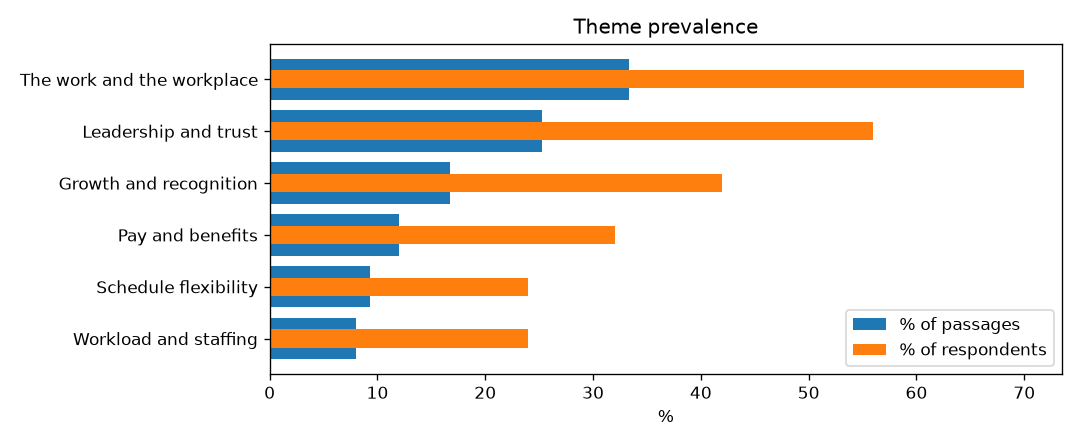

In [10]:
chart = themes.export_paths.get("theme_prevalence.png")
if chart:
    display(Image(filename=chart))
else:
    print("No prevalence chart. Install the plots extra (matplotlib).")


## Multi-seed stability

`amulti_seed_stability` runs open coding once per seed, concurrently, and compares labels. The seed changes document order. It does not pick a winning codebook. Label overlap is descriptive: open codes are not expected to match string for string when the model is a live one.

This offline coder applies the same keyword rules no matter the reading order, so the Jaccard on this run is 1. That shows the comparison working. It does not show that a provider would be that stable. The second call passes the other seeds into `aevaluate`, which then fills Chen's coverage, overlap, novelty, and divergence, plus an adjusted Rand index on passage-to-code assignments.


In [11]:
from automated_grounded_theory import amulti_seed_stability

report = await amulti_seed_stability(
    corpus,
    context,
    [1, 4, 7],
    model=model,
    unit="speaker_turn",
    batch_size=3,
    concurrency=2,
    sweep_every=25,
    review_mode="document",
    pipeline=True,
    output_dir=Path(tempfile.mkdtemp(prefix="agt-demo-stability-")),
)
print(report.note)
print("seeds", report.seeds)
print("mean Jaccard", report.mean_jaccard, "mean soft Jaccard", report.mean_soft_jaccard)
print("codes in every seed", len(report.stable_codes))
print("codes in only one seed", report.codes_in_only_one_seed or "none")

compared = await aevaluate(report.runs[0], CONTEXT_PATH, other_sources=report.runs[1:])
chen = compared["chen_metrics"]
print("adjusted Rand index", compared.get("adjusted_rand_index"))
if isinstance(chen, dict):
    print(
        "Chen mean coverage", chen.get("mean_coverage"),
        "overlap", chen.get("mean_overlap"),
        "novelty", chen.get("mean_novelty"),
        "divergence", chen.get("mean_divergence"),
    )
else:
    print(chen)


Exact Jaccard uses case-folded code labels. Soft Jaccard greedily matches labels, or label-plus-definition text, at token overlap 0.5. Neither score decides which seed is correct, and neither is a validity coefficient. Open-coding labels are expected to move.
seeds [1, 4, 7]
mean Jaccard 1.0 mean soft Jaccard 1.0
codes in every seed 32
codes in only one seed none
adjusted Rand index 1.0
Chen mean coverage 1.0 overlap 1.0 novelty 0.0 divergence 0.0


## Export to Taguette

Open coding writes `taguette_codebook.csv`. The theme report writes `taguette_themes.csv`, with a parent row for the theme and a child row `Theme\Code`. Taguette's importer (`Project info` → `Import codebook`) reads a `tag` or `name` or `path` column and an optional `description`. The hierarchy separator in Taguette's own tests is a backslash (`interesting\places`).

Taguette does not import highlights, and it does not import `.qdc`. `highlights.csv` and the `.qdc` files follow shapes other QDA tools can read. After import, a highlight filter can use the path prefix, but the codebook tree in the Taguette UI is still a flat list of those paths.

1. Finish a project in Taguette and open **Project info**.
2. Choose **Import codebook**.
3. Upload the `taguette_codebook.csv` printed below for the open codes, or `taguette_themes.csv` for the themes. Both files are written to a temporary directory.
4. Confirm the theme rows use a backslash, for example `Pay and benefits\wanting better pay`.
5. Code highlights in Taguette yourself. This package does not push highlights into Taguette.


In [12]:
def preview(path, limit=8):
    file_path = Path(path)
    print(file_path)
    lines = file_path.read_text(encoding="utf-8").splitlines()
    print("\n".join(lines[:limit]))
    print()

preview(result.export_paths["taguette_codebook.csv"])
preview(themes.export_paths["taguette_themes.csv"], limit=12)
print("qdc written", Path(result.export_paths["codebook.qdc"]).name, Path(themes.export_paths["taguette_themes.qdc"]).name)


/tmp/agt-demo-ly05fwei/taguette_codebook.csv
tag,description,number of highlights,number of documents
valuing schedule flexibility,"Incidents of valuing schedule flexibility.

Examples:
- ""I like the hybrid schedule but wish it was more consistent across teams"" (R015)
- ""more flexibility for warehouse staff, the office gets hybrid and we get nothing"" (R011)
- ""Love the remote flexibility, it's the main reason I stay despite the below-market pay."" (R011)",14,12
staying for the team,"Incidents of staying for the team.

/tmp/agt-demo-themes-lizz99hl/taguette_themes.csv
tag,description,number of highlights,number of documents
The work and the workplace,"Incidents about tools, the building, coworkers, and what the work is for.",52,51
The work and the workplace\staying for the team,"Incidents about tools, the building, coworkers, and what the work is for.

Incidents of staying for the team.",13,12
The work and the workplace\fighting clunky systems,"Incidents about tools, the building, 